Load the necessary modules.

In [1]:
import intake
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from xhistogram.xarray import histogram
from dask.distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 28
Total threads: 28,Total memory: 125.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:43793,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:33345,Total threads: 1
Dashboard: /proxy/35351/status,Memory: 4.47 GiB
Nanny: tcp://127.0.0.1:33017,


In [3]:
catalog = intake.cat.access_nri
experiment = '01deg_jra55v13_ryf9091' # the RYF90-91 experiment

esm_ds = catalog[experiment]
esm_ds

,unique
filename,3469
path,11947
file_id,22
frequency,5
start_date,3361
end_date,3360
variable,205
variable_long_name,197
variable_standard_name,36
variable_cell_methods,3


Note that the bathymetry provided by `ht` is not discretised into the same bins as `st_ocean(_edges)`.

### 1. Define your region of interest. 
Bathymetry variables, `ht`, are used for masking unwanted deep regions on the continental shelf and shallow regions offshore.

In [5]:
# Search for bathymetry - on u and t grid. 
esm_ds.search(variable=['ht'])

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='ht' → variable=['ht','ht']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)


,unique
filename,1
path,1116
file_id,1
frequency,1
start_date,1116
end_date,1116
variable,20
variable_long_name,20
variable_standard_name,2
variable_cell_methods,2


They're both in a single dataset, so we can load them together using `.to_dask()`. We use `xarray_open_kwargs = {'chunks' : "auto"}` to let dask determine the chunks. We also set `"decode_timedelta" : False` to disable a bunch of useless warnings related to a library change.


In [7]:
bathy = esm_ds.search(variable=['ht']).to_dask(
    xarray_open_kwargs={
        "chunks" : "auto",
    }
)

ht = bathy['ht']

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


As a simple example, we mask out everything but the Ross Sea shallower than 2000 meters.
Alternatively, users can define any polygon as their mask.

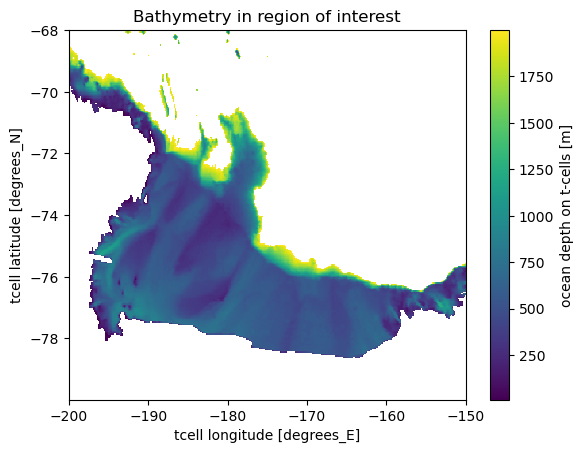

In [8]:
# Define the region of interest
lon_slice = slice(-200, -150)
lat_slice = slice(-80, -68)
mask_depth = 2000

# select correct extent of ht, hu for use later:
ht = ht.sel(xt_ocean=lon_slice).sel(yt_ocean=lat_slice)

# create masks:
mask_t = ht.sel(xt_ocean=lon_slice).sel(yt_ocean=lat_slice) < mask_depth
mask_t = mask_t.where(mask_t != 0)

# mask bathymetry:
ht_masked = ht * mask_t

# Plot the bathymetry in the mask region:
ht_masked.plot()
plt.title('Bathymetry in region of interest')
plt.show()

### 2. Import variables for averaging, set up thickness and area for weighting, and isobath bins.

In [9]:
# Import properties to average along isobaths.

# Define the start and end times #
start_time, end_time = '2170-01-01', '2179-12-16'
# For searching with the intake catalog, we can use wildcard searches: so start_date = '217[0,9].*' means any date starting with 2170,2171..2179
# See https://access-nri-intake-catalog.readthedocs.io/en/latest/usage/quickstart.html#data-discovery for more info

# Define the variables we want to load
variables =['salt','temp','pot_rho_0','u','v', 'dzt']

esm_ds.search(variable=variables,frequency='1mon', start_date='217[0,9].*')

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='salt' → variable=['salt','salt']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='temp' → variable=['temp','temp']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='pot_rho_0' → variable=['pot_rho_0','pot_rho_0']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='u' → variable=['u','u']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/dat

,unique
filename,1
path,8
file_id,1
frequency,1
start_date,8
end_date,8
variable,46
variable_long_name,42
variable_standard_name,11
variable_cell_methods,2


All our variables are in the one dataset - so we can load them all at once - this is more efficient than doing things separately

In [10]:
# Load the dataset
var_dataset = esm_ds.search(
    variable=variables,frequency='1mon', start_date='217[0,9].*'
).to_dask(
    xarray_open_kwargs={
        'chunks' : "auto",
    }
)
# Select out slice
var_dataset = var_dataset.sel(time=slice(start_time, end_time)).sel(yt_ocean=lat_slice).sel(yu_ocean=lat_slice)

# Separate our variables into data arrays
temp = var_dataset['temp']
salt = var_dataset['salt']
density = var_dataset['pot_rho_0']
u = var_dataset['u']
v = var_dataset['v']
dzt = var_dataset['dzt']

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='salt' → variable=['salt','salt']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='temp' → variable=['temp','temp']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='pot_rho_0' → variable=['pot_rho_0','pot_rho_0']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='u' → variable=['u','u']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/dat

#### For ease of computation, we bilinearly interpolate the u field onto the horizontal t field using xESMF

In [11]:
%%time
import xesmf as xe

ds_out = xr.Dataset()
ds_out['u'] = var_dataset['u'].rename({'xu_ocean':'lon', 'yu_ocean':'lat'})
ds_in = xr.Dataset()
ds_in['temp'] = var_dataset['temp'].rename({'xt_ocean':'lon', 'yt_ocean':'lat'})

regridder = xe.Regridder(ds_out, ds_in, "bilinear")
u_interped = regridder(u).rename({'lon':'xt_ocean', 'lat':'yt_ocean'})


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/xesmf/frontend.py:788: UserWarning: Using dimensions ('yu_ocean', 'xu_ocean') from data variable u as the horizontal dimensions for the regridding.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/xarray/computation/apply_ufunc.py:312: PerformanceWarning: Regridding is increasing the number of chunks by a factor of 5.0, you might want to specify sizes in `output_chunks` in the regridder call. Default behaviour is to preserve the chunk sizes from the input (284, 800).
  result_var = func(*data_vars)


CPU times: user 1min 9s, sys: 17.5 s, total: 1min 27s
Wall time: 1min


Compute volume and area for weighted averaging using `xhistogram` package, using time-varying grid cell thickness `dzt`

In [12]:
esm_ds.search(variable='st_ocean', frequency='1mon').unique().file_id

['ocean.1mon.grid_xt_ocean:3600.grid_xu_ocean:3600.grid_yt_ocean:2700.grid_yu_ocean:2700.neutral:80.neutralrho_edges:81.nv:2.potrho:80.potrho_edges:81.st_edges_ocean:76.st_ocean:75.sw_edges_ocean:76.sw_ocean:75.xt_ocean:3600.xu_ocean:3600.yt_ocean:2700.yu_ocean:2700',
 'ocean.1mon.nv:2.st_edges_ocean:76.st_ocean:75.xt_ocean:3600.yt_ocean:2700']

In [13]:
%%time
grid_vars = ['xt_ocean','yt_ocean','st_edges_ocean','st_ocean']
coord_ds = esm_ds.search(
    variable=grid_vars, 
    file_id='ocean.1mon.grid_xt_ocean:3600.grid_xu_ocean:3600.grid_yt_ocean:2700.grid_yu_ocean:2700.neutral:80.neutralrho_edges:81.nv:2.potrho:80.potrho_edges:81.st_edges_ocean:76.st_ocean:75.sw_edges_ocean:76.sw_ocean:75.xt_ocean:3600.xu_ocean:3600.yt_ocean:2700.yu_ocean:2700',
    frequency='1mon'
).to_dask(
    xarray_open_kwargs={
        'chunks' : "auto",
    }
)
xt_ocean = coord_ds['xt_ocean'].sel(xt_ocean=lon_slice)
yt_ocean = coord_ds['yt_ocean'].sel(yt_ocean=lat_slice)
st_ocean = coord_ds['st_ocean']

st_edges_ocean = coord_ds['st_edges_ocean']

# area_t is in a different dataset - so we need to load it separately.
area_t = esm_ds.search(variable='area_t').to_dask(
    xarray_open_kwargs={
        'chunks' : "auto",
        "decode_timedelta" : False,
    }
)['area_t']

area_t = area_t.sel(yt_ocean=lat_slice)

volume = area_t * dzt

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='xt_ocean' → variable=['xt_ocean','xt_ocean']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='yt_ocean' → variable=['yt_ocean','yt_ocean']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='st_edges_ocean' → variable=['st_edges_ocean','st_edges_ocean']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='st_ocean' → variable=['st_ocean','st_ocean']
  

CPU times: user 33.3 s, sys: 26.3 s, total: 59.7 s
Wall time: 53.4 s


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


In [15]:
### MASK YOUR REGION OF INTEREST ###

volume_masked = volume * mask_t
area_t_masked = area_t * mask_t
temp_masked = temp * mask_t
u_masked = u_interped * mask_t

### 3. Bin variables into isobath depth!

Here, we bin the variables of interest by isobath using the `xhistogram` package.

First, we define the edges of the isobath bins. It does make sense for these to be the same as `st_edges_ocean` because that is the rough vertical resolution of the ACCESS-OM2-01 model.

In [16]:

bins_isobath = st_edges_ocean.values

# Next, we sum the volume-weighted variable of interest along that isobath using xhistogram
V_sum = histogram(ht_masked, bins = bins_isobath,
                  dim = ['yt_ocean', 'xt_ocean'],
                  weights = volume_masked)
A_sum = histogram(ht_masked, bins = bins_isobath,
                  dim = ['yt_ocean', 'xt_ocean'],
                  weights = area_t_masked)

TV_sum = histogram(ht_masked, bins = bins_isobath,
                   dim = ['yt_ocean', 'xt_ocean'],
                   weights = volume_masked * temp_masked)

uV_sum = histogram(ht_masked, bins = bins_isobath,
                   dim = ['yt_ocean', 'xt_ocean'],
                   weights = u_masked * volume_masked)

# Finally, we divide the summed, volume-weighted variable of interest by volume, to get a mean along an isobath

T_mean = TV_sum / V_sum
u_mean = uV_sum / V_sum

The binning above creates an averaged field as a function of isobath.

Let's plot this to see what it looks like!

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_c

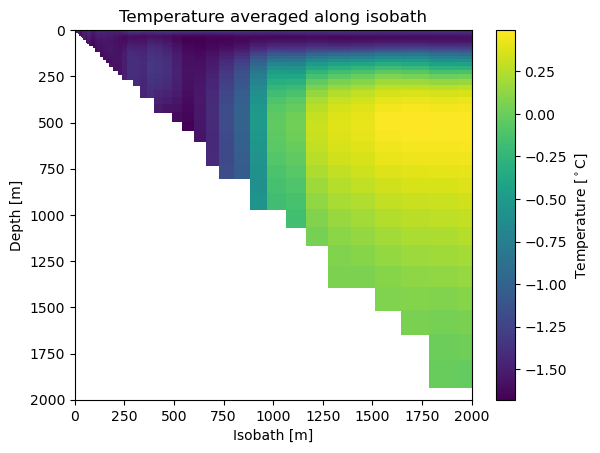

In [18]:
plt.pcolor(T_mean.ht_bin, temp_masked.st_ocean, T_mean.mean('time')-273.15)
plt.gca().invert_yaxis()
plt.ylim(2000,0)
plt.xlim(0,2000)
plt.xlabel('Isobath [m]')
plt.ylabel('Depth [m]')
plt.colorbar(label = 'Temperature [$^\circ$C]')
plt.title('Temperature averaged along isobath');

## Each variable is averaged along isobaths, so the bathymetry looks diagonal in the plot #

We can rescale the isobath (x-axis) to be scaled by the cumulative surface area covered by each isobath, from shallowest to deepest. This produces a "normalised area" or pseduo-latitude $x$-axis.

In [20]:
normalised_area_cumsum = (A_sum.cumsum('ht_bin') / np.nansum(A_sum)).values

lat_max, lat_min = abs(mask_t.yt_ocean.max().values), abs(mask_t.yt_ocean.min().values)

## Here, we plot the averaged quantities as a function of normalised area (between 0 and 1)
## and pseudo-latitude
def normalised_to_pseudo_lat(normalised_area):
    return -1 * (lat_min - (lat_min - lat_max) * normalised_area)

def pseudo_lat_to_normalised(pseudo_lat):
    return (lat_min + pseudo_lat) / (lat_min - lat_max)

pseudo_lat = normalised_to_pseudo_lat(normalised_area_cumsum)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 93.68 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
 

CPU times: user 20.5 s, sys: 8.32 s, total: 28.8 s
Wall time: 34.8 s


ValueError: dimensions () must have the same length as the number of data dimensions, ndim=1

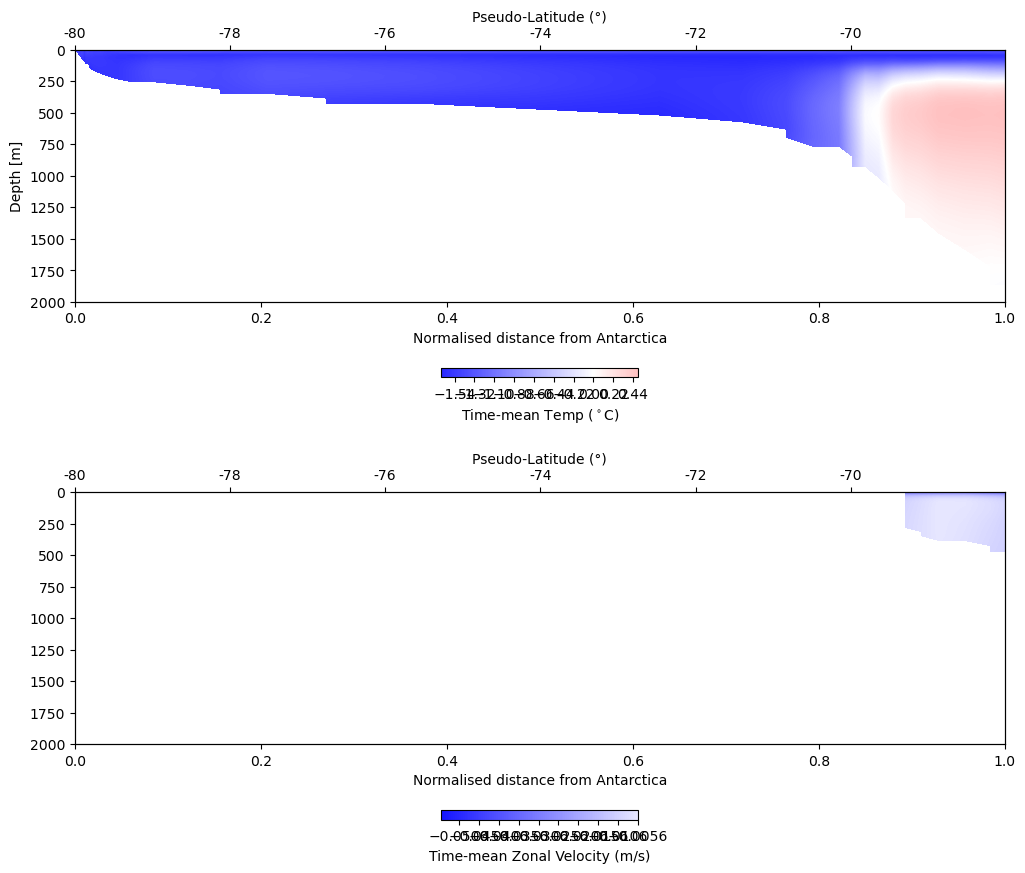

In [21]:
%%time
## Finally, plot the isobath-averaged properties. This should take about 3 minutes on a Large ARE Instance


fig, axs = plt.subplots(2, 1, figsize=(12, 10), facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = 0.35, wspace=0.2)
axs = axs.ravel()

fontsize = 13

im1 = axs[0].contourf(normalised_area_cumsum, st_ocean, T_mean.mean('time') - 273.15, levels=500,
                      vmin=-2, vmax=2, cmap=plt.cm.bwr)
im4 = axs[1].contourf(normalised_area_cumsum, st_ocean, u_mean.mean('time'), levels=500,
                      vmin=-0.06, vmax=0.06, cmap=plt.cm.bwr)

density_contours = np.linspace(1027.7, 1028, 5)

for i, ax in enumerate(axs):
    ax.invert_yaxis()
    ax.set_xlabel('Normalised distance from Antarctica')
    ax.set_ylim(mask_depth, 0)

    # Secondary x-axis: pseudo_lat
    twin_ax = ax.twiny()
    twin_ax.set_xlim(ax.get_xlim())  # Align the limits to match the shared x-axis
    twin_ax.set_xticks(pseudo_lat_to_normalised(np.arange(-80, -68, 2)))  # Match tick positions
    twin_ax.set_xticklabels(np.arange(-80, -68, 2))  # Replace tick labels with pseudo_lat values
    twin_ax.set_xlabel('Pseudo-Latitude (°)')

axs[0].set_ylabel('Depth [m]')

cb1 = plt.colorbar(im1, ax=axs[0], fraction=0.03, pad=0.2, orientation='horizontal')
cb4 = plt.colorbar(im4, ax=axs[1], fraction=0.03, pad=0.2, orientation='horizontal')

cb1.set_label('Time-mean Temp ($^\circ$C)')
cb4.set_label('Time-mean Zonal Velocity (m/s)')

cb1.set_ticks(np.linspace(np.min(T_mean.mean('time') - 273.15), np.max(T_mean.mean('time') - 273.15), 5))
cb4.set_ticks(np.linspace(np.min(u_mean.mean('time')), np.max(u_mean.mean('time')), 4))

plt.suptitle('Isobath-averaged properties', y=0.95);


# Along-isobath averaging

This recipe averages ocean properties **within depth bins** on the Antarctic continental shelf and slope in ACCESS-OM2-01. In some areas of the slope, these depth bins align and follow isobaths at the slope, and so this averaging is essentially an along isobath average. This is not guaranteed to happen everywhere! Read Caveat 1. below. 

The method works for scalar fields (here temperature) and for vector components that have **not** been rotated into along/across-isobath directions (here the $x$-velocity `u`). It does not rotate velocities, so `u` stays the model grid's $x$-component (eastward at these latitudes).

For every grid cell in the region we know its bottom depth $h$ (`ht`). We group the cells into isobath bins $[h_b, h_{b+1})$ and, at each depth level $z$ and time $t$, compute a volume-weighted mean:

$$
\overline{T}(t, z, h_b) = \frac{\sum_{h_b \le h < h_{b+1}} T\,V}{\sum_{h_b \le h < h_{b+1}} V}, \qquad V = \texttt{area\_t} \times \texttt{dzt}
$$

The sums are computed with [`xhistogram`](https://xhistogram.readthedocs.io), using `ht` as the binned quantity and $V$ (or $T V$) as the weights.

The steps are:

1. Load the bathymetry `ht` and build a mask for the region of interest (the Ross Sea, shallower than 2000 m).
2. Load temperature, velocity and cell thickness `dzt`, interpolate `u` onto the tracer grid, and build the cell volume from `area_t` and `dzt`.
3. Bin the volume-weighted fields by isobath and divide by the binned volume.
4. Plot the results against isobath depth, then against the cumulative fraction of shelf area (a "pseudo-latitude").

#### Caveats

1. **The mask matters.** A deep trough on the shelf gets averaged with the slope offshore at the same depth. A seamount offshore gets averaged with the shallow shelf. Check that your region contains only the topography you mean to compare.
2. **Bins near the sea floor are partial.** Bottom depths `ht` include partial bottom cells, so they do not line up with the vertical levels `st_ocean`. A bin can therefore mix columns whose deepest wet cell is in different levels. As a result, the lowest one or two levels of each isobath column hold fewer cells than the levels above them.

#### Compute requirements

This recipe was run on a **Large** ARE instance (28 cores, ~125 GiB). Interpolating `u` takes about 1 minute, and the final figure takes a few minutes. Smaller instances may run out of memory.

The notebook was run with `PYTHONWARNINGS="ignore"` set in the environment variables. We don't recommend this in general, because it can hide useful information. If you run it without that setting, expect a number of warnings from `intake`, `xesmf` and `dask`.

#### Converting to MOM6

The method doesn't depend on the model, but the names do. For a MOM6 run (e.g. ACCESS-OM3) the closest equivalents are:

| ACCESS-OM2 (MOM5) | MOM6 |
|---|---|
| `temp` (K) | `thetao` (°C) |
| `u` (B-grid, `xu_ocean`, `yu_ocean`) | `uo` (C-grid, `xq`, `yh`) |
| `dzt` | `thkcello` |
| `area_t` | `areacello` |
| `ht` | `deptho` |
| `st_ocean`, `st_edges_ocean` | `z_l`, `z_i` (or the model's native vertical coordinate) |
| `xt_ocean`, `yt_ocean` | `xh`, `yh` |

Note that MOM6 temperature is already in °C, so you would drop the `- 273.15` used below.

In [1]:
import intake
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from xhistogram.xarray import histogram
from dask.distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 34195 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/34195/status,
Dashboard: /proxy/34195/status,Workers: 28
Total threads: 28,Total memory: 125.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40071,Workers: 0
Dashboard: /proxy/34195/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:42213,Total threads: 1
Dashboard: /proxy/35353/status,Memory: 4.47 GiB
Nanny: tcp://127.0.0.1:37513,


## Load the data
We use the 0.1° repeat-year-forcing experiment `01deg_jra55v13_ryf9091`, forced every year with the same JRA55-do atmosphere (May 1990 to April 1991). First we load the bathymetry and decide the region of interest.

In [7]:
catalog = intake.cat.access_nri
experiment = '01deg_jra55v13_ryf9091' # the RYF90-91 experiment

esm_ds = catalog[experiment]
bathy = esm_ds.search(variable=['ht'], frequency='fx').to_dask()
ht = bathy['ht']

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='ht' → variable=['ht','ht']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


For this example, we will select a small region of the shelf and slope in Ross sector. We will also create a mask to only retain depths shallower than 2000m to exclude these from the "along-isobath" average.

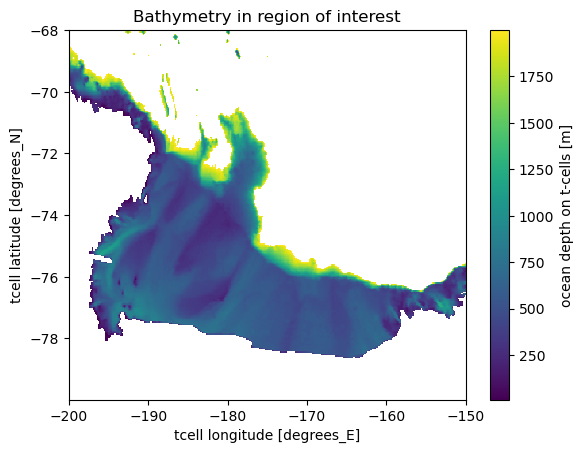

In [8]:
# Define the region of interest
lon_slice = slice(-200, -150)
lat_slice = slice(-80, -68)
mask_depth = 2000

# select correct extent of ht, hu for use later:
ht = ht.sel(xt_ocean=lon_slice).sel(yt_ocean=lat_slice)

# create masks:
mask_t = ht.sel(xt_ocean=lon_slice).sel(yt_ocean=lat_slice) < mask_depth
mask_t = mask_t.where(mask_t != 0)

# mask bathymetry:
ht_masked = ht * mask_t

# Plot the bathymetry in the mask region:
ht_masked.plot()
plt.title('Bathymetry in region of interest')
plt.show()

Now we can load the rest of the diagnostics needed in this example. We will need temperature (`temp`) which is on tracer cells. To weight the averages we need each cell's volume, $V = \texttt{area\_t} \times \texttt{dzt}$, where `dzt` is the thickness of the cells. Because `dzt` changes with time (sea level moves), $V$ is a function of time too. Note that if you want to choose diagnostics in other grids, you will have to adapt the calculation of volume. 

We will use a preprocessing function to only extract the region of interest, and open a single (random) year.

In [34]:
def preprocess(ds):
    ds = ds.sel(xt_ocean=lon_slice, yt_ocean=lat_slice)
    return ds

var_dataset = esm_ds.search(variable=['temp','dzt'],
                            frequency='1mon', 
                            start_date='217[0].*').to_dask(preprocess=preprocess)
temp = var_dataset['temp']-273.15
dzt = var_dataset['dzt']
area_t = esm_ds.search(variable=['area_t'], frequency='fx').to_dask(preprocess=preprocess)['area_t']

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='temp' → variable=['temp','temp']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='dzt' → variable=['dzt','dzt']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='area_t' → variable=['area_t','area_t']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimensi

We also need the depth levels `st_ocean` and their edges `st_edges_ocean`, which are stored in the monthly grid file. The catalog has more than one monthly file with these coordinates, so we first list their `file_id`s and then select the one that matches the 3600 × 2700 grid.

In [35]:
coord_ds = esm_ds.search(
    variable=['xt_ocean','yt_ocean','st_edges_ocean','st_ocean'], 
    file_id='ocean.1mon.grid_xt_ocean:3600.grid_xu_ocean:3600.grid_yt_ocean:2700.grid_yu_ocean:2700.neutral:80.neutralrho_edges:81.nv:2.potrho:80.potrho_edges:81.st_edges_ocean:76.st_ocean:75.sw_edges_ocean:76.sw_ocean:75.xt_ocean:3600.xu_ocean:3600.yt_ocean:2700.yu_ocean:2700',
    frequency='1mon'
).to_dask()
xt_ocean = coord_ds['xt_ocean'].sel(xt_ocean=lon_slice)
yt_ocean = coord_ds['yt_ocean'].sel(yt_ocean=lat_slice)
st_ocean = coord_ds['st_ocean']
st_edges_ocean = coord_ds['st_edges_ocean']

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='xt_ocean' → variable=['xt_ocean','xt_ocean']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='yt_ocean' → variable=['yt_ocean','yt_ocean']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='st_edges_ocean' → variable=['st_edges_ocean','st_edges_ocean']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.09/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='st_ocean' → variable=['st_ocean','st_ocean']
  

In [36]:
volume = area_t * dzt

Now lets apply the region mask to the volume, area and temperature.

In [37]:
volume_masked = volume * mask_t
area_t_masked = area_t * mask_t
temp_masked = temp * mask_t

## Bin the variables by depth

For the isobath bin edges we use `st_edges_ocean`, the edges of the model's vertical levels. This makes the isobath resolution match the vertical resolution - there's not much point in trying to bin into finer bins.

`xhistogram.histogram` sums its `weights` over all cells (`yt_ocean`, `xt_ocean`) applying the bins to `ht_masked`. It keeps the other dimensions (`time`, `st_ocean`), so each result has dimensions `(time, st_ocean, ht_bin)`. We compute:

- `V_sum`: the volume in each bin and level,
- `A_sum`: the horizontal area in each bin (used for the pseudo-latitude axis in step 4),
- `TV_sum`: the volume-weighted sums of temperature.

The isobath means are then `T_mean = TV_sum / V_sum`. All of these are lazy dask arrays: nothing is computed until we plot.

In [40]:
depth_bins = st_edges_ocean.values

V_sum = histogram(ht_masked, bins = depth_bins,
                  dim = ['yt_ocean', 'xt_ocean'],
                  weights = volume_masked)
A_sum = histogram(ht_masked, bins = depth_bins,
                  dim = ['yt_ocean', 'xt_ocean'],
                  weights = area_t_masked)
TV_sum = histogram(ht_masked, bins = depth_bins,
                   dim = ['yt_ocean', 'xt_ocean'],
                   weights = volume_masked * temp_masked)

T_mean = TV_sum / V_sum.where(V_sum>0)

## 4. Plot the isobath-averaged fields

First we plot the time-mean temperature (converted from K to °C) against isobath depth. The data stop along a diagonal: an isobath bin $h$ has no water below depth $h$, so the sea floor appears as the line *depth = isobath*.

The time mean here is a plain mean over the monthly records, not weighted by the number of days in each month.

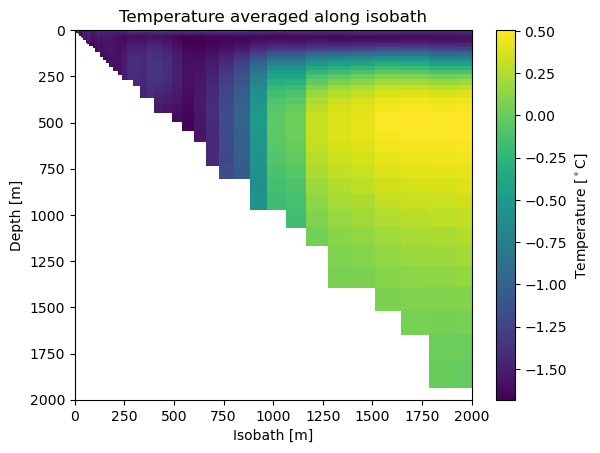

In [41]:
plt.pcolor(T_mean.ht_bin, temp_masked.st_ocean, T_mean.mean('time'))
plt.gca().invert_yaxis()
plt.ylim(2000,0)
plt.xlim(0,2000)
plt.xlabel('Isobath [m]')
plt.ylabel('Depth [m]')
plt.colorbar(label = 'Temperature [$^\circ$C]')
plt.title('Temperature averaged along isobath');

### Rescale the x-axis by area

The isobath axis gives as much width to a 2000 m bin with little area as to a shelf bin covering a large area. Instead, we can place each bin at the **cumulative fraction of horizontal area** shallower than it (`normalised_area_cumsum`, from 0 at the coast to 1 at the 2000 m limit). On this axis, distance is proportional to the area of shelf and slope covered.

We also map this fraction linearly onto the region's latitude range (80°S at 0, 68°S at 1) to give a "pseudo-latitude" axis. This is only a relabelling of the 0–1 axis, not the actual latitude of the isobaths.

In [42]:
normalised_area_cumsum = (A_sum.cumsum('ht_bin') / np.nansum(A_sum)).values

lat_max, lat_min = abs(mask_t.yt_ocean.max().values), abs(mask_t.yt_ocean.min().values)

## Here, we plot the averaged quantities as a function of normalised area (between 0 and 1)
## and pseudo-latitude
def normalised_to_pseudo_lat(normalised_area):
    return -1 * (lat_min - (lat_min - lat_max) * normalised_area)

def pseudo_lat_to_normalised(pseudo_lat):
    return (lat_min + pseudo_lat) / (lat_min - lat_max)

pseudo_lat = normalised_to_pseudo_lat(normalised_area_cumsum)

Finally, we plot time-mean temperature against the normalised area, with the pseudo-latitude on a secondary axis at the top. 

In the saved run this cell raised a `ValueError` at the `cb1.set_ticks(...)` line, because `np.linspace` was given xarray objects rather than plain numbers. The panels drew, but the colourbar ticks, colourbar labels and title were not set (see *Issues* below).

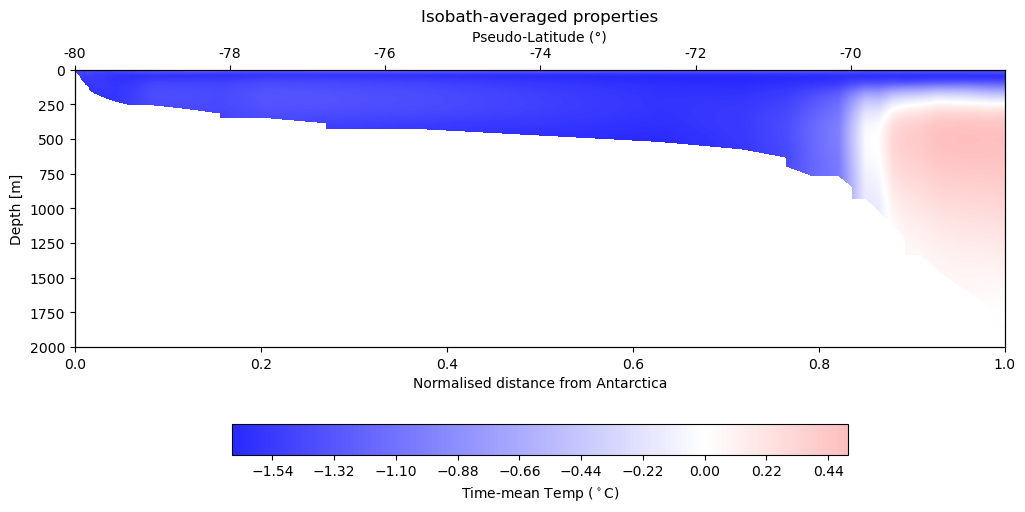

In [50]:
fig, axs = plt.subplots(1, 1, figsize=(12, 5), facecolor='w', edgecolor='k')
fig.subplots_adjust(hspace = 0.35, wspace=0.2)

im1 = axs.contourf(normalised_area_cumsum, st_ocean, T_mean.mean('time'), levels=500,
                   vmin=-2, vmax=2, cmap=plt.cm.bwr)

axs.invert_yaxis()
axs.set_xlabel('Normalised distance from Antarctica')
axs.set_ylim(mask_depth, 0)

# Secondary x-axis: pseudo_lat
twin_ax = axs.twiny()
twin_ax.set_xlim(axs.get_xlim())  # Align the limits to match the shared x-axis
twin_ax.set_xticks(pseudo_lat_to_normalised(np.arange(-80, -68, 2)))  # Match tick positions
twin_ax.set_xticklabels(np.arange(-80, -68, 2))  # Replace tick labels with pseudo_lat values
twin_ax.set_xlabel('Pseudo-Latitude (°)')

axs.set_ylabel('Depth [m]')

cb1 = plt.colorbar(im1, fraction=0.08, pad=0.2, orientation='horizontal')

cb1.set_label('Time-mean Temp ($^\circ$C)')

plt.title('Isobath-averaged properties');

In [51]:
client.close()